<a href="https://colab.research.google.com/github/sankalp19projects/boiling-point-prediction/blob/main/boiling_point_complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Boiling-point prediction: complete notebook

This notebook contains **all training and prediction code**; it does not import `train.py` or `predict.py`.

**Inputs:** molecular weight (g/mol), critical temperature (K), and dimensionless acentric factor. **Target:** `boiling point (K)`.

The original evaluated model was an equal-weight Extra Trees + support-vector regression ensemble, with test MAE **7.04 K**, RMSE **13.19 K**, and R² **0.9798** on 1,284 records. Those are reference results; cells below compute results from the data you supply. R² is not percentage accuracy.

## How to run

1. Open in Jupyter, VS Code, or Google Colab. In Colab, upload `data_file.csv` using the Files sidebar.
2. Place `data_file.csv` beside the notebook, or use the `data/` folder in the earlier model package. Set `DATA_PATH` explicitly if needed.
3. Install dependencies if needed, then run cells in order. The default `RUN_TRAINING = True` runs the complete comparison and evaluation.
4. To use the already trained model, set `RUN_TRAINING = False` and set `SAVED_MODEL_PATH` to its `model.joblib`. Training sections will be skipped.

All new results are written to `notebook_results/`. The original package's `results/` is preserved.

**Scope:** these are internal dataset results. The original sources, pressure conditions, and possible use of boiling point to estimate input properties remain unverified. This is a property-based predictor, not a name-only or structure-only predictor.

## 1. Dependencies

Python 3.11 or 3.12 is recommended for a fresh environment. Uncomment the installation line below only if needed, then restart the kernel before continuing. Pinned modeling versions reproduce the original environment. On macOS, if XGBoost reports a missing OpenMP library, install `libomp` using Homebrew in a terminal.

In [1]:
# Uncomment if the packages are not installed:
# %pip install numpy==2.0.2 pandas==2.2.3 scipy==1.15.2 scikit-learn==1.6.1 xgboost==2.1.4 joblib==1.4.2 "matplotlib>=3.9,<4" "threadpoolctl>=3.5,<4"

In [2]:
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from threadpoolctl import threadpool_limits
from xgboost import XGBRegressor

FEATURES = ['molweight', 'critical temperature (K)', 'acentric factor']
TARGET = 'boiling point (K)'
SEED = 42

from IPython.display import display, Image

# Avoid oversubscribing CPU threads during cross-validation.
thread_limiter = threadpool_limits(limits=4)

## 2. Configuration and data location

In [5]:
RUN_TRAINING = True  # False loads an existing model and skips all fitting.

# Change these paths if your files are elsewhere.
DATA_PATH = Path("data_file.csv")
SAVED_MODEL_PATH = Path("results/model.joblib")
out = Path("notebook_results")

# Convenient fallbacks for the previously supplied ZIP's folder layout.
if RUN_TRAINING and not DATA_PATH.exists():
    for alternative in [Path("data/data_file.csv"), Path("boiling_point_model/data/data_file.csv")]:
        if alternative.exists():
            DATA_PATH = alternative
            break
if not SAVED_MODEL_PATH.exists():
    for alternative in [Path("model.joblib"), Path("boiling_point_model/results/model.joblib"), out/"model.joblib"]:
        if alternative.exists():
            SAVED_MODEL_PATH = alternative
            break
if RUN_TRAINING and not DATA_PATH.exists():
    raise FileNotFoundError("Upload data_file.csv or set DATA_PATH to its location.")
if not RUN_TRAINING and not SAVED_MODEL_PATH.exists():
    raise FileNotFoundError("Set SAVED_MODEL_PATH to the previously trained model.joblib.")
source = DATA_PATH
print("Mode:", "full training" if RUN_TRAINING else "load saved model")
print("Output directory:", out)

Mode: full training
Output directory: notebook_results


## 3. Metrics and grouping

MAE is the primary selection metric. Errors in Kelvin and Celsius have the same magnitude. A connected-component group links rows with either the same normalized compound name or the same three numerical inputs. This also follows transitive links. Keeping each group together prevents these known duplicates from crossing the split; it cannot identify unrecognized aliases or molecular families.

In [6]:
def metrics(y, p):
    e = np.abs(np.asarray(y) - np.asarray(p))
    return dict(mae_K=float(e.mean()), rmse_K=float(np.sqrt(mean_squared_error(y, p))),
                r2=float(r2_score(y, p)), median_absolute_error_K=float(np.median(e)),
                within_5K_pct=float(100*np.mean(e <= 5)),
                within_10K_pct=float(100*np.mean(e <= 10)),
                within_20K_pct=float(100*np.mean(e <= 20)),
                p90_absolute_error_K=float(np.quantile(e, .9)))

In [7]:
def groups_for(df):
    # Connected components prevent overlap through either names OR feature tuples.
    parent = list(range(len(df)))
    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    def union(a, b):
        a, b = root(a), root(b)
        parent[max(a, b)] = min(a, b)
    seen_name, seen_x = {}, {}
    for i, row in df.iterrows():
        name = str(row['name']).strip().casefold()
        key = tuple(float(row[c]) for c in FEATURES)
        if name in seen_name: union(i, seen_name[name])
        if key in seen_x: union(i, seen_x[key])
        seen_name[name], seen_x[key] = i, i
    return np.array([root(i) for i in range(len(df))])

## 4. Audit and clean the data

Exclude nonfinite values, nonpositive mass/absolute temperatures, exact duplicate rows (ignoring the source index), and a row whose boiling point is not below its critical temperature. Exclude the two carbon-dioxide records because at atmospheric pressure they describe sublimation, not normal boiling. Quarantine records are saved with reasons.

Conflicting targets and unusual compounds are **retained** rather than removed to improve the score. The supplied file retains 6,027 of 6,031 rows. It contains 224 groups with identical numerical inputs but different targets, which limits the information these inputs can provide.

In [8]:
def prepare(source, out):
    raw = pd.read_csv(source)
    df = raw.rename(columns={'Unnamed: 0': 'source_id'}).copy()
    if 'source_id' not in df: df.insert(0, 'source_id', np.arange(len(df)))
    for col in FEATURES + [TARGET]: df[col] = pd.to_numeric(df[col], errors='coerce')
    reason = pd.Series('', index=df.index)
    reason.loc[~np.isfinite(df[FEATURES+[TARGET]]).all(axis=1)] = 'nonfinite numeric data'
    reason.loc[(df[['molweight', 'critical temperature (K)', TARGET]] <= 0).any(axis=1)] = 'nonpositive mass or absolute temperature'
    reason.loc[df[TARGET] >= df['critical temperature (K)']] = 'boiling point >= critical temperature; quarantine'
    reason.loc[df['name'].str.strip().str.casefold() == 'carbon dioxide'] = 'CO2 sublimation at atmospheric pressure; not normal boiling'
    dup = df.duplicated(subset=['name'] + FEATURES + [TARGET])
    reason.loc[dup & reason.eq('')] = 'exact duplicate excluding source index'
    excluded = df.loc[reason.ne('')].copy()
    excluded['reason'] = reason[reason.ne('')]
    excluded.to_csv(out/'excluded_rows.csv', index=False)
    clean = df.loc[reason.eq('')].reset_index(drop=True)
    clean['group_id'] = groups_for(clean)
    clean.to_csv(out/'cleaned_data.csv', index=False)
    repeated = clean[clean['name'].str.strip().str.casefold().duplicated(keep=False)]
    repeated.to_csv(out/'repeated_names_for_review.csv', index=False)
    conflict = clean.groupby(FEATURES, dropna=False)[TARGET].agg(['size','min','max'])
    conflict['spread_K'] = conflict['max'] - conflict['min']
    conflict[conflict.spread_K > 0].sort_values('spread_K', ascending=False).to_csv(out/'conflicting_inputs.csv')
    audit = dict(raw_rows=len(raw), cleaned_rows=len(clean), excluded_rows=len(excluded),
                 exclusion_reasons=excluded.reason.value_counts().to_dict(),
                 groups=int(clean.group_id.nunique()),
                 conflicting_input_groups=int((conflict.spread_K > 0).sum()),
                 source_sha256=hashlib.sha256(Path(source).read_bytes()).hexdigest(),
                 source_provenance='User-supplied CSV; original measurement and feature provenance unknown',
                 note='Conflicting retained targets are not averaged or removed based on model errors.')
    return clean, audit

In [9]:
if RUN_TRAINING:
    out.mkdir(parents=True, exist_ok=True)
    raw = pd.read_csv(source)
    required = ['name'] + FEATURES + [TARGET]
    missing = sorted(set(required) - set(raw.columns))
    if missing:
        raise ValueError(f"Missing dataset columns: {missing}")
    print("Original shape:", raw.shape)
    display(raw.head())
    df, audit = prepare(source, out)
    display(pd.Series(audit, name="audit"))
    display(pd.read_csv(out/"excluded_rows.csv"))

Original shape: (6031, 6)


,Unnamed: 0,name,molweight,critical temperature (K),acentric factor,boiling point (K)
0,1,(+)-a-pinene,136.23704,647.00,0.341,428.65
1,2,(+)-camphene,136.23704,638.00,0.296,432.65
2,3,(-)-a-pinene,136.23704,647.00,0.341,429.35
3,4,(-)-b-citronellol,156.26820,656.59,0.612,498.65
4,5,(-)-camphene,136.23704,638.00,0.296,439.95


,audit
raw_rows,6031
cleaned_rows,6027
excluded_rows,4
exclusion_reasons,{'CO2 sublimation at atmospheric pressure; not...
groups,4301
conflicting_input_groups,224
source_sha256,4b5b862eba02b282aae5d4ddd620fec3fb22dd6d96d493...
source_provenance,User-supplied CSV; original measurement and fe...
note,Conflicting retained targets are not averaged ...


,source_id,name,molweight,critical temperature (K),acentric factor,boiling point (K),reason
0,4193,bismuth pentafluoride,303.972386,470.00,0.5040,503.15,boiling point >= critical temperature; quarantine
1,4271,carbon dioxide,44.009800,304.19,0.2276,194.70,CO2 sublimation at atmospheric pressure; not n...
2,4272,carbon dioxide,44.009800,304.19,0.2280,194.67,CO2 sublimation at atmospheric pressure; not n...
3,4479,cyanogen chloride,61.470440,449.00,0.3200,286.00,exact duplicate excluding source index


## 5. Freeze the test set and define cross-validation

Reserve 20% of **groups** with seed 42. This gives 4,743 training rows and 1,284 test rows for the original CSV. Group sizes differ, so the row fraction need not equal 20%.

Five-fold grouped cross-validation runs only on training data. Scalers belong inside pipelines so they fit only on each training fold. Test labels are not used for model selection. Once the final test is evaluated, do not keep changing the search to improve that test score; new development needs a fresh independent test set.

In [10]:
if RUN_TRAINING:
    train_i, test_i = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(df, groups=df.group_id))
    tr, te = df.iloc[train_i].reset_index(drop=True), df.iloc[test_i].reset_index(drop=True)
    assert set(tr.group_id).isdisjoint(set(te.group_id))
    assert set(tr['name'].str.strip().str.casefold()).isdisjoint(set(te['name'].str.strip().str.casefold()))
    assert set(map(tuple,tr[FEATURES].to_numpy())).isdisjoint(set(map(tuple,te[FEATURES].to_numpy())))
    split = df[['source_id','name','group_id']].copy()
    split['split'] = 'train'
    split.loc[test_i,'split'] = 'test'
    split.to_csv(out/'split_manifest.csv', index=False)
    X, y = tr[FEATURES], tr[TARGET]
    folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, tr.group_id))
    tr['cv_fold'] = -1
    for f, (_, va) in enumerate(folds): tr.loc[va,'cv_fold'] = f
    tr[['source_id','group_id','cv_fold']].to_csv(out/'cv_manifest.csv', index=False)
    audit.update(training_rows=len(tr), test_rows=len(te), training_groups=int(tr.group_id.nunique()), test_groups=int(te.group_id.nunique()))
    (out/'audit.json').write_text(json.dumps(audit, indent=2))
    print('AUDIT', json.dumps(audit), flush=True)

    display(tr[FEATURES + [TARGET]].describe())

AUDIT {"raw_rows": 6031, "cleaned_rows": 6027, "excluded_rows": 4, "exclusion_reasons": {"CO2 sublimation at atmospheric pressure; not normal boiling": 2, "boiling point >= critical temperature; quarantine": 1, "exact duplicate excluding source index": 1}, "groups": 4301, "conflicting_input_groups": 224, "source_sha256": "4b5b862eba02b282aae5d4ddd620fec3fb22dd6d96d4931cbe44b22b7a72f288", "source_provenance": "User-supplied CSV; original measurement and feature provenance unknown", "note": "Conflicting retained targets are not averaged or removed based on model errors.", "training_rows": 4743, "test_rows": 1284, "training_groups": 3440, "test_groups": 861}


,molweight,critical temperature (K),acentric factor,boiling point (K)
count,4743.000000,4743.000000,4743.000000,4743.000000
mean,162.556631,650.739612,0.489962,460.481801
std,75.506001,109.605258,0.206718,95.990659
min,16.042760,132.920000,0.010500,81.700000
25%,115.218720,587.200000,0.330000,400.895000
50%,146.229720,638.890000,0.445000,455.000000
75%,182.349440,721.650000,0.650500,514.150000
max,626.327880,1314.000000,1.116000,797.080000


## 6. Define the full model search

Compare 27 individual candidates: a median baseline, linear and polynomial Ridge, RBF support-vector regression, Extra Trees, histogram gradient boosting, and XGBoost. CatBoost is not part of this implemented search. Select by pooled out-of-fold MAE. Then consider one predefined equal-weight average of the best two candidates.

The winning CV score is affected by model selection; use the reserved test set for the final performance claim.

In [11]:
def candidates():
    models = {'median_baseline': DummyRegressor(strategy='median'),
              'linear_ridge': make_pipeline(StandardScaler(), Ridge(alpha=1))}
    for degree in (2, 3, 4):
        for alpha in (.1, 10.):
            models[f'polynomial_{degree}_ridge_{alpha}'] = make_pipeline(
                StandardScaler(), PolynomialFeatures(degree=degree, include_bias=False),
                StandardScaler(), Ridge(alpha=alpha))
    for c in (100, 500, 2000):
        for gamma in (.05, .3):
            models[f'svr_C{c}_g{gamma}'] = make_pipeline(StandardScaler(), SVR(C=c, gamma=gamma, epsilon=2))
    for leaf in (1, 3, 8):
        models[f'extra_trees_leaf{leaf}'] = ExtraTreesRegressor(n_estimators=300,
            min_samples_leaf=leaf, max_features=1., random_state=SEED, n_jobs=4)
    for leaf in (15, 31):
        for l2 in (1, 10):
            models[f'hist_boost_leaves{leaf}_l2{l2}'] = HistGradientBoostingRegressor(
                max_iter=350, learning_rate=.05, max_leaf_nodes=leaf,
                l2_regularization=l2, early_stopping=False, random_state=SEED)
    for depth in (2, 3, 5):
        for reg in (1, 10):
            models[f'xgboost_depth{depth}_l2{reg}'] = XGBRegressor(n_estimators=600,
                max_depth=depth, learning_rate=.035, min_child_weight=5,
                reg_lambda=reg, subsample=.9, colsample_bytree=1.,
                objective='reg:squarederror', tree_method='hist', n_jobs=4, random_state=SEED)
    return models

In [12]:
def cv_predict(model, X, y, folds):
    pred = np.empty(len(y))
    errors = []
    for tr, va in folds:
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        pred[va] = fitted.predict(X.iloc[va])
        errors.append(mean_absolute_error(y.iloc[va], pred[va]))
    return pred, errors

## 7. Train and compare all candidates using training folds only

In [13]:
if RUN_TRAINING:
    models, results, predictions = candidates(), [], {}
    for name, model in models.items():
        start = time.monotonic()
        p, errs = cv_predict(model, X, y, folds)
        predictions[name] = p
        result = {'model':name, **metrics(y,p), 'fold_mae_std_K':float(np.std(errs)), 'seconds':round(time.monotonic()-start,2)}
        results.append(result)
        pd.DataFrame(results).sort_values('mae_K').to_csv(out/'cv_results.csv', index=False)
        print('CV',name,'MAE',round(result['mae_K'],4),'seconds',result['seconds'],flush=True)

CV median_baseline MAE 72.7032 seconds 0.02
CV linear_ridge MAE 12.6087 seconds 0.06
CV polynomial_2_ridge_0.1 MAE 9.6275 seconds 0.09
CV polynomial_2_ridge_10.0 MAE 9.6435 seconds 0.06
CV polynomial_3_ridge_0.1 MAE 9.3442 seconds 0.07
CV polynomial_3_ridge_10.0 MAE 9.4093 seconds 0.06
CV polynomial_4_ridge_0.1 MAE 9.2475 seconds 0.44
CV polynomial_4_ridge_10.0 MAE 9.2485 seconds 0.3
CV svr_C100_g0.05 MAE 8.6908 seconds 5.87
CV svr_C100_g0.3 MAE 7.768 seconds 8.78
CV svr_C500_g0.05 MAE 8.4696 seconds 7.41
CV svr_C500_g0.3 MAE 7.4605 seconds 8.87
CV svr_C2000_g0.05 MAE 8.3411 seconds 11.02
CV svr_C2000_g0.3 MAE 7.4514 seconds 25.56
CV extra_trees_leaf1 MAE 6.934 seconds 10.76
CV extra_trees_leaf3 MAE 7.4593 seconds 5.32
CV extra_trees_leaf8 MAE 9.0056 seconds 5.63
CV hist_boost_leaves15_l21 MAE 8.2194 seconds 2.47
CV hist_boost_leaves15_l210 MAE 8.2673 seconds 2.46
CV hist_boost_leaves31_l21 MAE 7.8074 seconds 4.38
CV hist_boost_leaves31_l210 MAE 7.7954 seconds 5.81
CV xgboost_depth2_l2

## 8. Evaluate the blend and freeze the selected model

In [14]:
if RUN_TRAINING:
    ranking = sorted(results, key=lambda r:r['mae_K'])
    # One predeclared equal-weight blend of the top two CV models; no test selection.
    top = [r['model'] for r in ranking[:2]]
    blend_p = np.mean([predictions[n] for n in top],axis=0)
    blend_name = 'equal_blend_top2'
    blend_result = {'model':blend_name, **metrics(y,blend_p),
                    'fold_mae_std_K':float(np.std([mean_absolute_error(y.iloc[v],blend_p[v]) for _,v in folds]))}
    results.append(blend_result)
    models[blend_name] = VotingRegressor([(f'm{i}',clone(models[n])) for i,n in enumerate(top)],n_jobs=1)
    predictions[blend_name] = blend_p
    pd.DataFrame(results).sort_values('mae_K').to_csv(out/'cv_results.csv', index=False)
    best_name = min(results, key=lambda r:r['mae_K'])['model']
    winner = models[best_name]
    (out/'selection.json').write_text(json.dumps({'selected_model':best_name,'selection_metric':'pooled grouped 5-fold OOF MAE','blend_members':top,'parameters':str(winner)},indent=2))
    print('SELECTED',best_name,flush=True)
    oof = tr[['source_id','name','group_id','cv_fold',TARGET]].copy()
    oof['prediction_K'] = predictions[best_name]
    oof['absolute_error_K'] = np.abs(y-oof.prediction_K)
    oof.to_csv(out/'training_oof_predictions.csv', index=False)

    display(pd.DataFrame(results).sort_values("mae_K").reset_index(drop=True))

SELECTED equal_blend_top2


,model,mae_K,rmse_K,r2,median_absolute_error_K,within_5K_pct,within_10K_pct,within_20K_pct,p90_absolute_error_K,fold_mae_std_K,seconds
0,equal_blend_top2,6.882412,13.178749,0.981147,3.223001,62.260173,80.012650,92.936960,16.593473,0.370955,NaN
1,extra_trees_leaf1,6.934025,12.895932,0.981947,3.213933,60.931900,79.148218,91.903858,17.643062,0.375665,10.76
2,svr_C2000_g0.3,7.451417,14.587015,0.976902,3.597141,60.510226,78.747628,91.819524,17.623215,0.322936,25.56
3,extra_trees_leaf3,7.459298,13.454465,0.980350,3.773060,57.685009,77.777778,91.946026,18.056604,0.304584,5.32
4,svr_C500_g0.3,7.460457,14.072352,0.978504,3.726321,60.109635,78.115117,91.566519,17.776329,0.289706,8.87
5,svr_C100_g0.3,7.768031,14.577415,0.976933,3.693942,59.139785,77.693443,90.786422,18.997299,0.276804,8.78
6,hist_boost_leaves31_l210,7.795417,13.706532,0.979607,3.987122,56.546490,76.133249,91.524352,18.566796,0.228554,5.81
7,hist_boost_leaves31_l21,7.807439,13.766383,0.979428,3.987504,56.609741,76.027830,91.018343,18.870568,0.286614,4.38
8,xgboost_depth5_l21,7.834209,13.520472,0.980157,4.121566,56.061564,76.175416,90.912924,19.045850,0.305822,2.41
9,xgboost_depth5_l210,7.939625,13.638786,0.979808,4.225702,54.796542,75.690491,90.870757,18.730673,0.351402,5.18


## 9. Feature sensitivity analysis

Use the same selected configuration and training folds with fewer inputs. These variants are not separately retuned. This quantifies dependence on the inputs but does not establish that their values were measured independently of boiling point.

In [15]:
if RUN_TRAINING:
    # Sensitivity analysis uses the already fixed winner and training folds only.
    ablations = []
    for cols, label in [(FEATURES[:2],'without_acentric_factor'),([FEATURES[0]],'molecular_weight_only')]:
        p, errs = cv_predict(winner, X[cols], y, folds)
        ablations.append({'features':label, **metrics(y,p)})
        print('ABLATION',label,round(mean_absolute_error(y,p),4),flush=True)
    pd.DataFrame(ablations).to_csv(out/'feature_ablation_cv.csv',index=False)

    display(pd.DataFrame(ablations))

ABLATION without_acentric_factor 13.7296
ABLATION molecular_weight_only 30.8036


,features,mae_K,rmse_K,r2,median_absolute_error_K,within_5K_pct,within_10K_pct,within_20K_pct,p90_absolute_error_K
0,without_acentric_factor,13.729584,22.158227,0.946703,8.017972,34.767025,56.968164,78.853047,31.110098
1,molecular_weight_only,30.803591,50.260499,0.725788,16.739761,18.933165,33.881510,55.429053,70.908194


## 10. Fit the selected model and evaluate the untouched test set

The selected configuration is now fixed. Fit it using all training records, then compute test MAE, RMSE, R² and tolerance-based percentages. The baseline predicts the training median.

Resample test **groups** 2,000 times to estimate a confidence interval for mean absolute error. This interval concerns uncertainty from the test sample; it is not an interval for a single prediction and does not address label validity.

In [16]:
if RUN_TRAINING:
    # Test labels are used here only after all choices are frozen.
    fitted = clone(winner).fit(X,y)
    p = fitted.predict(te[FEATURES])
    test_metrics = metrics(te[TARGET],p)
    baseline = clone(models['median_baseline']).fit(X,y).predict(te[FEATURES])
    # Group bootstrap describes uncertainty from this test sample, not label validity.
    rng = np.random.default_rng(SEED)
    group_errors = pd.DataFrame({'group':te.group_id, 'err':abs(te[TARGET]-p)}).groupby('group').err.agg(['sum','count'])
    boot = []
    for _ in range(2000):
        sampled = group_errors.iloc[rng.integers(0,len(group_errors),len(group_errors))]
        boot.append(sampled['sum'].sum()/sampled['count'].sum())
    test_metrics['mae_95pct_group_bootstrap_interval_K'] = list(map(float,np.quantile(boot,[.025,.975])))
    summary = {'selected_model':best_name,'cv_metrics':metrics(y,predictions[best_name]),
        'test_metrics':test_metrics,'test_median_baseline':metrics(te[TARGET],baseline),'audit':audit,
        'evaluation':'Frozen 20% group holdout. Groups connect normalized names or identical 3-feature tuples. No overlap on either key.',
        'limitations':['Original target pressure and measured-versus-estimated provenance are unverified.',
          'Critical temperature and acentric factor may have been estimated from boiling point; grouped splitting cannot remove this feature-level leakage.',
          'Inputs require molecular weight, critical temperature and acentric factor, not just a compound name.',
          'No molecular structures: different chemical families and name aliases may still cross the split.',
          'Conflicting labels and unverified sublimation/decomposition entries may remain.',
          'CV model-selection scores are optimistic; use the untouched test metrics for performance claims.',
          'The saved model is fitted only on the training partition; it is exactly the evaluated model.'],
        'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                    'scikit-learn':sklearn.__version__,'scipy':scipy.__version__,'xgboost':xgboost.__version__,'joblib':joblib.__version__}}
    (out/'metrics.json').write_text(json.dumps(summary,indent=2))

    display(pd.DataFrame({"selected_model": test_metrics, "median_baseline": summary["test_median_baseline"]}))

,selected_model,median_baseline
mae_K,7.012271,68.873178
rmse_K,13.086374,93.021646
r2,0.980146,-0.003162
median_absolute_error_K,3.184503,52.750000
within_5K_pct,62.227414,6.230530
within_10K_pct,78.660436,11.760125
within_20K_pct,91.978193,26.869159
p90_absolute_error_K,17.479665,156.000000
mae_95pct_group_bootstrap_interval_K,"[6.079255337097669, 8.02256300897878]",NaN


## 11. Save the evaluated model and verify reloading

The saved estimator is trained only on the training partition. It is the same model that produced the test score; it is not refitted on the test set. Save predictions, metadata, and input ranges with the estimator. Only load joblib files from sources you trust.

In [17]:
if RUN_TRAINING:
    te = te.copy()
    te['prediction_K'], te['prediction_C'] = p, p-273.15
    te['absolute_error_K'] = abs(te[TARGET]-p)
    te.to_csv(out/'test_predictions.csv',index=False)
    bundle = {'estimator':fitted,'features':FEATURES,'target':TARGET,'units':'K',
              'feature_min':X.min().to_dict(),'feature_max':X.max().to_dict(),
              'metadata':summary}
    joblib.dump(bundle,out/'model.joblib',compress=3)
    reloaded = joblib.load(out/'model.joblib')
    np.testing.assert_allclose(reloaded['estimator'].predict(te[FEATURES]),p,rtol=1e-10,atol=1e-10)

    print("Saved:", out/"model.joblib")
    print("Reloaded predictions match.")

Saved: notebook_results/model.joblib
Reloaded predictions match.


## 12. Plot held-out predictions and residuals

In [18]:
def make_plot(test,summary,out):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
    fig,axs = plt.subplots(1,2,figsize=(11,4.7),layout='constrained')
    actual,pred = test[TARGET],test.prediction_K
    axs[0].scatter(actual,pred,s=14,alpha=.5,c='#087f8c',edgecolors='none')
    lo,hi = min(actual.min(),pred.min())-10,max(actual.max(),pred.max())+10
    axs[0].plot([lo,hi],[lo,hi],color='#505c70',linestyle='--',linewidth=1)
    axs[0].set(xlabel='Dataset boiling point (K)',ylabel='Predicted boiling point (K)',title='Held-out predictions',xlim=(lo,hi),ylim=(lo,hi))
    axs[1].hist(pred-actual,bins=45,color='#087f8c',edgecolor='white')
    axs[1].axvline(0,color='#505c70',linestyle='--')
    axs[1].set(xlabel='Prediction − dataset value (K)',ylabel='Compounds / records',title='Test error distribution')
    m=summary['test_metrics']
    fig.suptitle(f"Boiling-point model | test MAE {m['mae_K']:.2f} K | R² {m['r2']:.4f}",fontsize=15,fontweight='bold')
    fig.savefig(out/'evaluation.png',dpi=170)
    plt.close(fig)

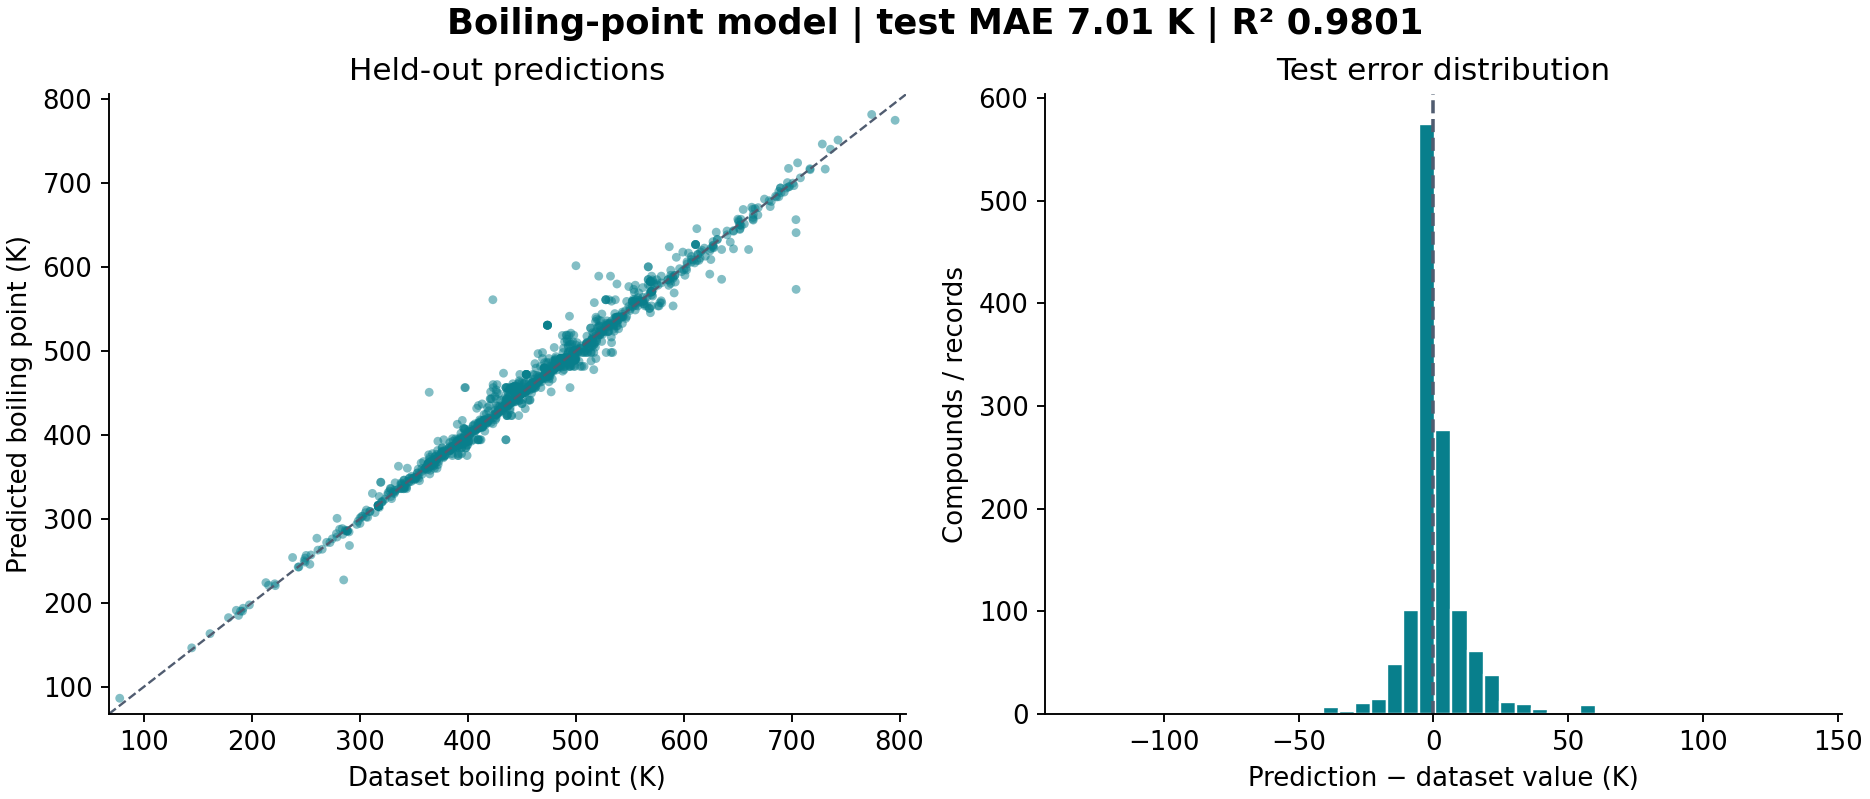

,name,boiling point (K),prediction_K,absolute_error_K
826,4-octylphenol,423.15,561.157882,138.007882
1188,phosphorus (red),704.15,573.521512,130.628488
1209,ruthenium (V) fluoride,500.15,601.704773,101.554773
143,"1,3-bis(methylthio)propane",364.15,450.818756,86.668756
139,"1,3,5-tri-tert-butylbenzene",521.25,589.264543,68.014543
1283,zirconium iodide,704.15,641.097532,63.052468
6,(S)-(+)-1-dimethylamino-2-propanol,397.15,456.374629,59.224629
190,1-(dimethylamino)-2-propanol,397.65,456.374629,58.724629
932,chlorine trifluoride,284.90,227.098162,57.801838
109,"1,2,4,5-tetraisopropylbenzene",532.15,589.264543,57.114543


In [19]:
if RUN_TRAINING:
    make_plot(te, summary, out)
    display(Image(filename=str(out/"evaluation.png")))
    # Inspect the largest errors transparently; do not delete them to raise the score.
    display(te.sort_values("absolute_error_K", ascending=False)[
        ["name", TARGET, "prediction_K", "absolute_error_K"]
    ].head(10))

## 13. Load the model for inference

With `RUN_TRAINING=True`, load the model just created. With `False`, load `SAVED_MODEL_PATH`. The following prediction cells work in either mode. Range checks flag obvious extrapolation; being within each individual range does not ensure that the combination is represented in training.

In [20]:
MODEL_PATH = out/"model.joblib" if RUN_TRAINING else SAVED_MODEL_PATH
loaded_bundle = joblib.load(MODEL_PATH)
display(pd.Series(loaded_bundle['metadata']['test_metrics'], name='saved_model_test_metrics'))

,saved_model_test_metrics
mae_K,7.012271
rmse_K,13.086374
r2,0.980146
median_absolute_error_K,3.184503
within_5K_pct,62.227414
within_10K_pct,78.660436
within_20K_pct,91.978193
p90_absolute_error_K,17.479665
mae_95pct_group_bootstrap_interval_K,"[6.079255337097669, 8.02256300897878]"


In [21]:
def predict(data, model_path=None):
    model_path = MODEL_PATH if model_path is None else Path(model_path)
    bundle = joblib.load(model_path)
    frame = pd.DataFrame(data).copy()
    features = bundle['features']
    missing = set(features)-set(frame.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
    X = frame[features].apply(pd.to_numeric,errors='raise')
    if len(X)==0: raise ValueError('No rows supplied')
    if not np.isfinite(X).all().all(): raise ValueError('Inputs must be finite numbers')
    if (X[['molweight','critical temperature (K)']]<=0).any().any():
        raise ValueError('Molecular weight and critical temperature in Kelvin must be positive')
    outside = np.zeros(len(X),dtype=bool)
    for col in features:
        outside |= ((X[col]<bundle['feature_min'][col]) | (X[col]>bundle['feature_max'][col])).to_numpy()
    frame['predicted_boiling_point_K'] = bundle['estimator'].predict(X)
    frame['predicted_boiling_point_C'] = frame.predicted_boiling_point_K-273.15
    frame['outside_training_feature_ranges'] = outside
    frame['physical_consistency_warning'] = (frame.predicted_boiling_point_K<=0) | (frame.predicted_boiling_point_K>=X['critical temperature (K)'])
    if outside.any(): warnings.warn('Some inputs are outside training ranges; extrapolation is unreliable.')
    if frame.physical_consistency_warning.any(): warnings.warn('Some predictions violate basic temperature consistency; review these inputs/results.')
    return frame

## 14. Predict one compound

Replace these three illustrative property values with your inputs. They are not an independently validated prediction for a named new compound. `name` is optional and does not affect the prediction.

In [22]:
new_compound = [{
    "name": "example",
    "molweight": 136.23704,
    "critical temperature (K)": 647.0,
    "acentric factor": 0.341,
}]
display(predict(new_compound))

,name,molweight,critical temperature (K),acentric factor,predicted_boiling_point_K,predicted_boiling_point_C,outside_training_feature_ranges,physical_consistency_warning
0,example,136.23704,647.0,0.341,439.141561,165.991561,False,False


## 15. Batch prediction

Set `BATCH_PATH` to an input CSV containing the three exact column names. This cell runs only when the file exists. Predictions include Kelvin, Celsius, range flags, and physical-consistency flags. Do not supply boiling points to the predictor as an input feature.

In [23]:
BATCH_PATH = Path("new_compounds.csv")
if BATCH_PATH.exists():
    batch_predictions = predict(pd.read_csv(BATCH_PATH))
    out.mkdir(parents=True, exist_ok=True)
    batch_predictions.to_csv(out/"batch_predictions.csv", index=False)
    display(batch_predictions.head())
    print("Saved:", out/"batch_predictions.csv")
else:
    print("To run batch inference, upload new_compounds.csv or change BATCH_PATH.")
    display(pd.DataFrame(new_compound))

To run batch inference, upload new_compounds.csv or change BATCH_PATH.


,name,molweight,critical temperature (K),acentric factor
0,example,136.23704,647.0,0.341


## 16. Interpretation and limitations

- R² of approximately 0.98 is not 98% accuracy. Quote MAE, RMSE, and the percentage within a meaningful error tolerance.
- The dataset's original measurement sources, pressure conditions, and measured-versus-estimated status are unknown. Other sublimation/decomposition entries might remain.
- Critical temperature and acentric factor must be known independently at prediction time. Some estimation methods use boiling point to derive these inputs; that would create feature-level target leakage. Grouped splitting cannot correct that, and strong correlation alone does not prove it.
- Different chemical families and unrecognized synonyms can still span the split. Molecular structures are absent, so this is not a scaffold-separated assessment.
- The model cannot distinguish compounds with identical numerical inputs. Prediction from a name or SMILES requires verified structure mapping and additional molecular descriptors.
- The test score is a benchmark on the supplied data, not a guarantee for arbitrary new chemistry. The original provided model achieved MAE 7.04 K; your rerun's measured results above are authoritative for that run.

## References

- Dataset: the user's supplied `data_file.csv`; upstream provenance was not supplied.
- [NIST carbon dioxide phase-change data](https://webbook.nist.gov/cgi/cbook.cgi?ID=C124389&Mask=4): triple-point pressure is about 5.185 bar, above atmospheric pressure.
- [Chemicals: acentric-factor correlations](https://chemicals.readthedocs.io/chemicals.acentric.html): `LK_omega` uses boiling temperature.
- [scikit-learn: grouped cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html).
- [scikit-learn: data leakage](https://scikit-learn.org/stable/common_pitfalls.html).

In [24]:
bundle = {
    'estimator': fitted,
    'features': FEATURES,
    'target': TARGET,
    'units': 'K',
    'feature_min': X.min().to_dict(),
    'feature_max': X.max().to_dict(),
    'metadata': summary
}

joblib.dump(bundle, "boiling_point_model.pkl", compress=3)

['boiling_point_model.pkl']